[← Previous: Exploratory data analysis](02_eda.ipynb)

# Modelling

## Controlled model ladder

We build a sequence of models to examine what graph information adds to face geometry. Each stage introduces a specific source of information or learning mechanism.

| Stage | Model | Purpose of the comparison |
| --- | --- | --- |
| 1 | Face CNN + independent classifier | Establish what surface geometry alone can predict. |
| 1.5 | Geometry + shallow topology features | Test explicit Laplacian, Weisfeiler–Lehman, and graphlet features without learned message passing. |
| 2a | Frozen face CNN + Chebyshev GCN | Test learned message passing over fixed geometry embeddings. |
| 2b | Joint face CNN + Chebyshev GCN | Test whether adapting the geometry encoder together with message passing improves the representation. |
| 3a | Joint geometry + static edge-gated message passing | Introduce curve geometry to condition messages between neighboring faces. |
| 3b | Joint geometry + updated edge-gated message passing | Allow gates to depend on face states and update edge states between graph layers. |

The static edge variant still trains the curve encoder; “static” means that the encoded edge states are not updated between graph layers.


## Modelling approach

We use simple models that follow the course tutorials closely, retaining common components and training settings wherever applicable. Our purpose is to attribute improvements to the mechanisms introduced along the ladder, rather than reproduce UV-Net exactly or optimize the final score.

The full UV-Net segmentation model also concatenates a pooled whole-solid embedding with each face embedding and uses a larger classifier with normalization and dropout ([released implementation](https://github.com/AutodeskAILab/UV-Net/blob/main/uvnet/models.py)). We omit these additions and introduce graph mechanisms in stages. This keeps comparisons interpretable on MFCAD, where performance quickly approaches saturation.


## Stage 1: Geometry-only baseline

[Baseline working notebook](../working/model_baseline.ipynb)

The baseline predicts a machining-feature class for each face using only its sampled surface geometry. It consists of a shared face CNN followed by a shared classifier, applied independently to each face. Face adjacency and curve geometry are introduced in later stages.

![Geometry-only baseline architecture](../figures/baseline-architecture.svg)

### Face CNN

Each face enters as a seven-channel $10\times10$ grid containing position, surface normal, and trimming mask. Three $3\times3$ convolutional blocks increase the channel width from 7 to 64, 128, and 256. Each block uses batch normalization and LeakyReLU; stride 1 and padding 1 preserve the grid dimensions. This surface encoder follows UV-Net’s design.

Adaptive average pooling reduces the spatial grid to a 256-dimensional vector, which a linear projection, batch normalization, and LeakyReLU transform into a **64-dimensional face embedding**. Pooling occurs over samples within a face, so it introduces no whole-solid context.

### Classifier

A two-layer MLP maps the face embedding to 16 class logits:

$$\mathbf z_f=W_2\,\operatorname{ReLU}(W_1\mathbf h_f+\mathbf b_1)+\mathbf b_2,$$

where $\mathbf h_f\in\mathbb{R}^{64}$, the hidden layer has 128 units, and $\mathbf z_f\in\mathbb{R}^{16}$. The classifier uses the tutorial’s simple Linear–ReLU–Linear pattern. The CNN and classifier are trained jointly using face-level cross-entropy; the predicted class is the largest logit. This establishes how much can be learned from individual face geometry before introducing graph information.


### Training setup

All models use 20 epochs, Adam with learning rate 0.001, batches of 128 solids, and face-level cross-entropy. We report the final epoch for every variant. The baseline settings below are read from the saved run.


In [1]:
%matplotlib inline
%run scripts/model_evaluation.py
baseline = load_cached_run("baseline")
show_training_setup(baseline)

/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


,Value
Setting,
Epochs,20
Batch size (solids),128
Learning rate,0.001
Face embedding dimension,64
Classifier hidden dimension,128


### Learning curves

Training metrics accumulate during optimization; validation metrics are evaluated after each epoch.

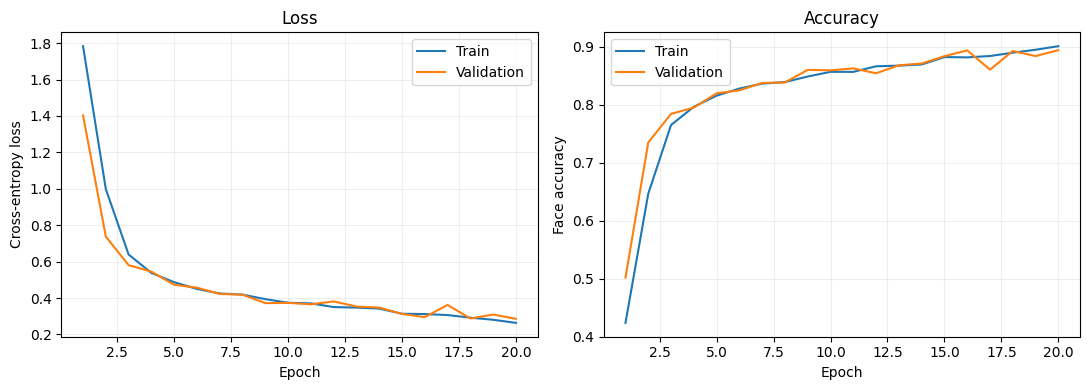

In [2]:
show_learning_curves(baseline)

### Final performance

The following metrics come from final-epoch evaluation. Mean IoU averages class IoUs over the full split, including stock; classes with zero union are excluded.


In [3]:
show_performance(baseline)

,faces,loss,accuracy,mean_iou
split,,,,
train,"209,847",0.2693,89.84%,80.17%
validation,"70,255",0.2863,89.44%,79.42%


## Stage 1.5: Geometry with shallow topology

We augment the baseline’s 64-dimensional face embedding with a fixed topology descriptor and train a per-face classifier. The main comparison freezes the baseline CNN, so the added descriptor is the new information source. These models introduce graph structure without learned message passing.

### Laplacian positional features

[Laplacian working notebook](../working/model_laplacian.ipynb)

For each solid, we form the symmetric normalized Laplacian $L=I-D^{-1/2}AD^{-1/2}$ and take the first eight non-zero-eigenvalue eigenvectors. Each face receives its row of this positional encoding, concatenated with its geometry embedding to form a 72-dimensional classifier input. Missing columns in small graphs are zero-padded. Random eigenvector sign flips during training account for sign ambiguity. The Laplacian retains the stored adjacency multiplicity.

![Geometry and Laplacian architecture](../figures/shallow-laplacian-architecture.svg)

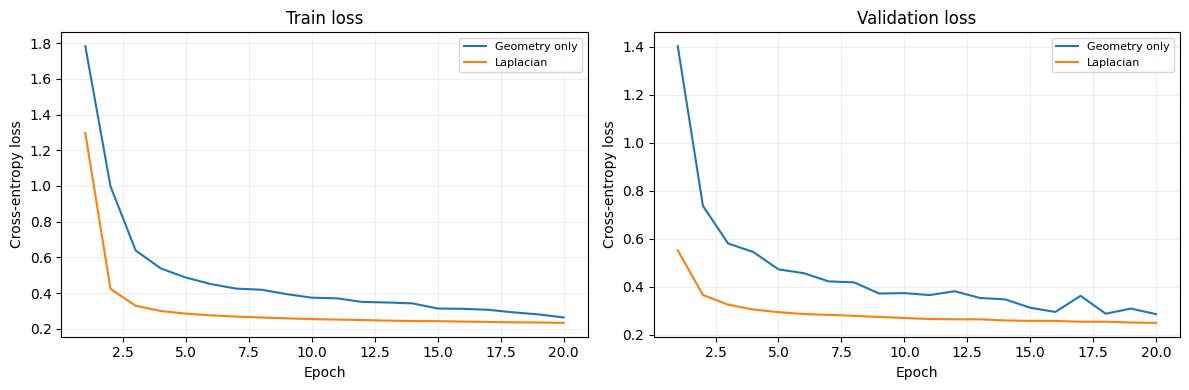

In [4]:
laplacian_comparison = compare_cached_runs({"Geometry only": "baseline", "Laplacian": "laplacian_frozen"})

With the face CNN frozen, Laplacian features raise validation accuracy from 89.44% to 90.97% and mean IoU from 79.42% to 82.39%.

### Weisfeiler–Lehman colour histories

[WL working notebook](../working/model_wl.ipynb)

Starting from the same colour for every face, $T$ rounds of 1-WL refinement combine a face’s current colour with the multiset of its neighbors’ colours. We retain the colour history from rounds 0–$T$ as categorical topology features. The vocabulary is fitted on training faces; unseen validation colours contribute zero. A sparse embedding lookup implements the categorical part of the classifier’s first linear layer, equivalent to concatenating one-hot colour histories with the face embedding.

We compare $T=3$ and $T=4$.

![Geometry and WL architecture](../figures/shallow-wl-architecture.svg)

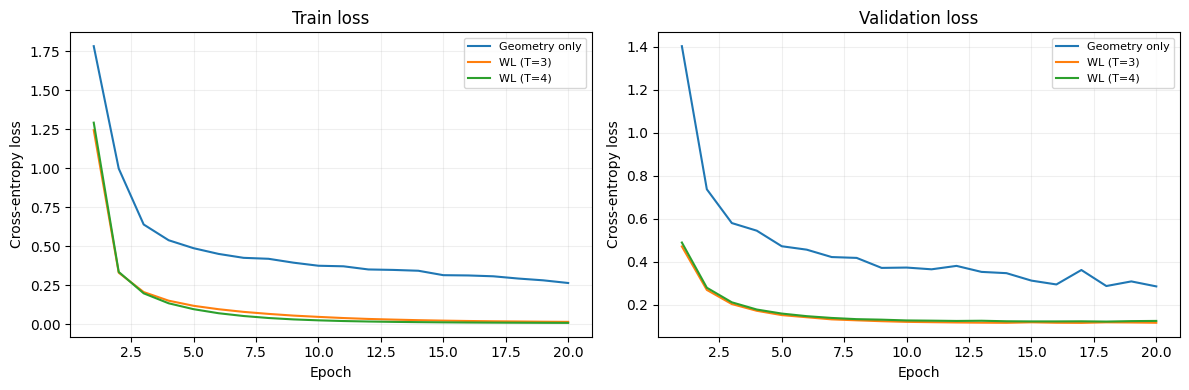

In [5]:
wl_comparison = compare_cached_runs({"Geometry only": "baseline", "WL (T=3)": "wl3_frozen", "WL (T=4)": "wl4_frozen"})


WL with three rounds reaches 95.66% validation accuracy and 90.32% mean IoU; four rounds slightly reduce these to 95.37% and 89.66%, despite higher training accuracy. We choose **WL with three rounds**, since the additional refinement increases the vocabulary without improving validation performance.


### Graphlet degree vectors

[Graphlet working notebook](../working/model_graphlet.ipynb)

We count each face’s participation in the 15 node orbits of connected induced graphlets with two to four nodes, following the shallow-learning tutorials. Size-$k$ counts are normalized by $\binom{N-1}{k-1}$ for a solid with $N$ faces, then standardized using training-set statistics. Concatenating the resulting 15-dimensional vector with geometry gives a 79-dimensional classifier input. WL and graphlet descriptors use simple undirected adjacency.

We also compare graphlets with up to five nodes, giving 73 orbit features and a 137-dimensional classifier input.

![Geometry and graphlet architecture](../figures/shallow-graphlet-architecture.svg)

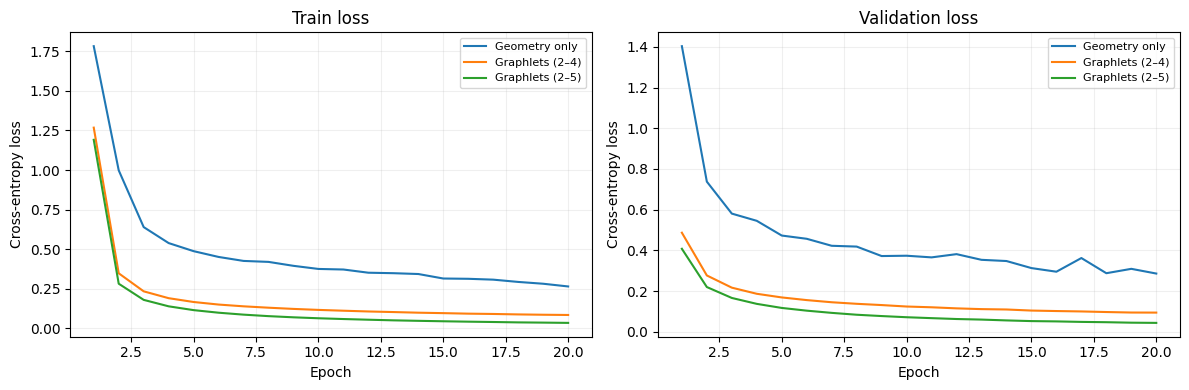

In [6]:
graphlet_comparison = compare_cached_runs({"Geometry only": "baseline", "Graphlets (2–4)": "graphlet4_frozen", "Graphlets (2–5)": "graphlet5_frozen"})


Four-node graphlets reach 96.55% validation accuracy and 92.33% mean IoU; five-node graphlets reach 98.71% and 96.85%. We retain **four-node graphlets** as a compact topology baseline; the additional improvement does not justify the larger descriptor and counting cost for our purpose.


### Comparison across shallow-topology models

We compare the shallow variants against the geometry-only baseline, keeping the face CNN frozen.


In [7]:
shallow_comparison = compare_cached_runs({
    "Geometry only": "baseline",
    "Laplacian": "laplacian_frozen",
    "WL (T=3)": "wl3_frozen",
    "WL (T=4)": "wl4_frozen",
    "Graphlets (2–4)": "graphlet4_frozen",
    "Graphlets (2–5)": "graphlet5_frozen",
}, show_curves=False)


Laplacian features give a modest improvement over geometry alone, while WL and graphlets give larger gains. We carry forward the eight-dimensional Laplacian encoding, three-round WL histories, and four-node graphlets as the shallow-topology comparisons. The larger variants provide context for these choices rather than adding further stages to the ladder.


## Stage 2: ChebNet GCN

[ChebNet working notebook](../working/model_chebyshev.ipynb)

We now learn how neighboring face embeddings contribute to each prediction. Following Graph Convnets Lab 01, we use a single Chebyshev graph-convolution layer with 64 output channels, followed by ReLU and the same 64 → 128 → 16 classifier structure. The graph filter operates on surface embeddings; curve geometry is introduced in the next stage.

![ChebNet GCN architecture](../figures/chebyshev-architecture.svg)

### Localized graph convolution

We form a simple undirected face-adjacency graph, merging parallel boundaries and removing self-loops. With the normalized Laplacian $L=I-D^{-1/2}AD^{-1/2}$, we use the spectral bound $\lambda_{\max}=2$ to obtain $\widetilde L=L-I$. The filter is

$$H'=\operatorname{ReLU}\left(\sum_{k=0}^{K}T_k(\widetilde L)H\Theta_k+b\right),$$

where $H$ contains the 64-dimensional face embeddings and the $\Theta_k$ are learned weights. The Chebyshev terms are computed recursively:

$$T_0(\widetilde L)H=H,\qquad T_1(\widetilde L)H=\widetilde L H,$$
$$T_k(\widetilde L)H=2\widetilde L\,T_{k-1}(\widetilde L)H-T_{k-2}(\widetilde L)H.$$

The main model uses polynomial degree $K=2$: three terms and at most two-hop graph reach. This is one graph-convolution layer, not two stacked layers. The zero-order term retains each face’s own information. We also compare $K=3$ to examine the effect of an additional hop. No eigendecomposition or graph pooling is required.

### Frozen and joint geometry

**Stage 2a** freezes the baseline face CNN and trains the graph filter and classifier. This isolates the gain from learning over neighboring geometry embeddings.

**Stage 2b** starts from the same baseline CNN weights but trains the CNN, graph filter, and classifier jointly. Comparing it with Stage 2a tests whether geometry representations benefit from adapting to their graph context. Both variants use 20 epochs, Adam with learning rate 0.001, and batches of 128 solids.

### Cached comparison


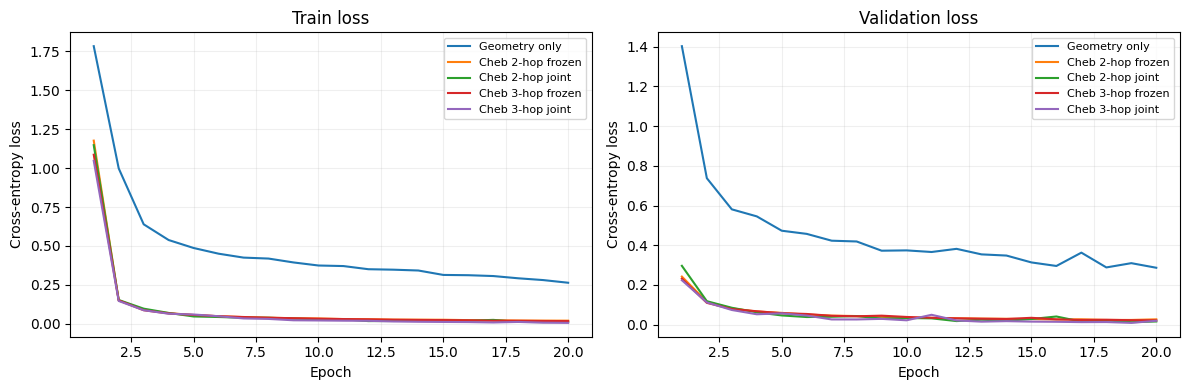

In [8]:
chebyshev_comparison = compare_cached_runs({
    "Geometry only": "baseline",
    "Cheb 2-hop frozen": "cheb2_frozen",
    "Cheb 2-hop joint": "cheb2_joint",
    "Cheb 3-hop frozen": "cheb3_frozen",
    "Cheb 3-hop joint": "cheb3_joint",
})

The two-hop frozen model reaches 99.09% validation accuracy and 98.21% mean IoU; joint training raises these to 99.51% and 98.93%. Three hops give a small gain with frozen geometry but do not improve on the two-hop joint model. We choose **two-hop ChebNet** for the frozen–joint comparison: it provides the strongest joint result with a smaller graph filter.


## Stage 3: Edge-conditioned message passing

[Edge-model working notebook](../working/model_edge.ipynb)

We now include the geometry of the boundary curves connecting faces. Following the residual gated GCN pattern in Graph Convnets Labs 04/05, both variants use two one-hop graph layers with 64-dimensional face and edge states, followed by a 64 → 128 → 16 per-face classifier. The face CNN starts from the geometry baseline and is trained jointly with the curve encoder and graph layers.

### Curve encoder

Each boundary curve provides ten samples with six channels: XYZ position and unit tangent. A 1D CNN uses three convolutional blocks with kernel size 3 and channel widths 6 → 64 → 128 → 256. Each block applies batch normalization and LeakyReLU. Average pooling over the ten samples and a 256 → 64 projection produce the edge embedding. The encoder follows UV-Net’s curve-encoding design.

We retain the original directed B-rep edges and their aligned curve grids, including parallel boundaries. The graph layers use the edge embeddings to weight incoming face messages. For a directed edge from face $j$ to face $i$, the feature-wise gate is $g_{ij}=\sigma(q_{ij})$. Incoming gates are normalized separately for each feature channel before weighting the neighboring face states. Each layer also includes a learned self transformation, graph-size normalization, batch normalization, ReLU, and a residual connection.

### Static edge gates

The static variant computes each layer’s gates from the original curve embedding:

$$q_{ij}^{(\ell)}=C^{(\ell)}e_{ij}^{(0)}.$$

The curve encoder is learned during training, but its output is held fixed between the two graph layers. This introduces geometry-dependent weights on neighboring faces.

![Static edge-gated model](../figures/edge-static-architecture.svg)

### Updated edge gates

The updated variant also conditions the gates on the current states of both endpoint faces:

$$q_{ij}^{(\ell)}=C^{(\ell)}e_{ij}^{(\ell)}+D^{(\ell)}h_i^{(\ell)}+E^{(\ell)}h_j^{(\ell)}.$$

After the first layer, a normalized residual update produces the edge states used by the second layer. Thus, the second layer can weight messages using both curve geometry and the face context learned in the first layer. Both variants retain two-hop graph reach and use the same 20-epoch Adam setup as the preceding models.

![Updated edge-gated model](../figures/edge-updated-architecture.svg)

### Cached comparison

We compare the two edge-gated variants with the geometry baseline and the two-hop joint ChebNet model. These edge models change the graph operator as well as adding curve geometry; the static–updated comparison focuses on endpoint-conditioned gating and edge-state updates within the same architecture.


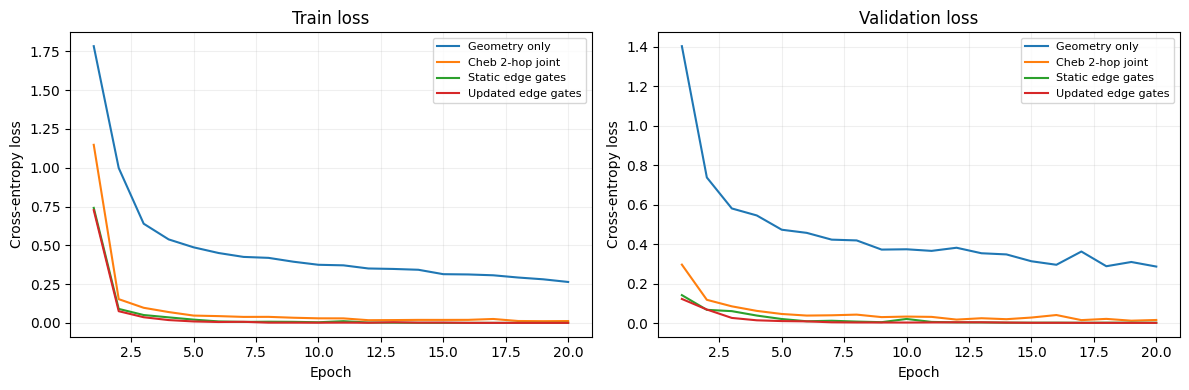

In [9]:
edge_comparison = compare_cached_runs({
    "Geometry only": "baseline",
    "Cheb 2-hop joint": "cheb2_joint",
    "Static edge gates": "edge_static",
    "Updated edge gates": "edge_updated",
})

The static edge-gated model reaches 99.95% validation accuracy and 99.87% mean IoU. Updating the edge gates raises these to 99.97% and 99.93%. Both reach 100% training accuracy. We retain **updated edge gates** as the final model because they give the best validation performance, while the static variant shows that most of the gain is already present without edge-state updates.


---

[← Previous: Exploratory data analysis](02_eda.ipynb) | [Next: Result analysis and conclusion →](04_result_analysis_and_conclusion.ipynb)